# Proyecto integrador final

<figure>
<a
href="https://colab.research.google.com/github/Adamychen/m10_quarto/blob/main/notebooks/evaluables/proyecto-final.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

> **Peso:** 60 % de la nota final.
>
> **Nota mínima:** 5,0 / 10.
>
> **Prerrequisitos:** tener completados y entregados todos los HPD 1-5.
>
> **Competencias:** [CE-1 a
> CE-6](../index.qmd#sec-competencias-especificas).
>
> **Base teórica:** [02f — Patrones de Diseño de
> Agentes](../bloque2/02f-patrones-agentes.qmd).

> **Variables de corrección**
>
> El script de corrección leerá las siguientes variables del notebook:
>
> | Variable | Valor | Descripción |
> |------------------------|------------------------|------------------------|
> | `proy_problema` | Texto corto | Problema que resuelve el proyecto |
> | `proy_patron` | Texto | Patrón de orquestación elegido — cadena, workflow o agente (de la taxonomía de 02f o propuesta propia) |
> | `proy_reporte` | Ruta al archivo de informe | Informe de evaluación en Markdown/PDF |
>
> Defínelas en la primera celda del notebook.

In [1]:
proy_problema = "Describe tu problema en una frase"
proy_patron = "planning"  # ej. cadena, react, routing, prompt-chaining, parallelization, orchestrator-workers, evaluator-optimizer, planning, reflection, multi-agente, propio...
proy_reporte = "informe_evaluacion.md"
print(f"Problema: {proy_problema} — Patrón: {proy_patron} — Informe: {proy_reporte}")

Problema: Describe tu problema en una frase — Patrón: planning — Informe: informe_evaluacion.md

## Descripción general

El proyecto integrador final es 100 % libre. Tú eliges el problema y el
patrón de orquestación con el que resolverlo — una cadena, un workflow o
un agente, o una variante propia —. El objetivo ya no es “construir un
RAG con agente”, sino diseñar, implementar y evaluar un sistema de
orquestación con LLM que resuelva un problema real de forma
demostrablemente eficaz.

Los HPD 1-5 ya garantizan que dominas las piezas técnicas (embeddings,
agentes con tool calling, workflows con LangGraph, MCP, RAG evaluado con
RAGAS). El proyecto es la prueba de que sabes integrarlas con criterio:
elegir la arquitectura adecuada para un problema, justificarla y
demostrar con evidencia que funciona mejor que una alternativa más
simple.

### La idea central

> **Tu proyecto en tres preguntas**
>
> 1.  **¿Qué problema resuelvo?** (y cómo se mide que está resuelto)
> 2.  **¿Qué patrón de orquestación elijo?** (cadena, workflow o agente
>     — y por qué, con la guía de selección de 02f)
> 3.  **¿Cómo demuestro que mi patrón aporta valor?** (comparándolo con
>     un baseline más simple)

Elige un patrón de la taxonomía de [02f — Patrones de Diseño de
Agentes](../bloque2/02f-patrones-agentes.qmd#sec-guia-seleccion) —
prompt chaining, routing, parallelization, orchestrator-workers,
evaluator-optimizer, ReAct, planning, reflection, multi-agente,
human-in-the-loop… — o propón una idea propia: una variante de un patrón
conocido o un patrón nuevo que se te ocurra. Las propuestas originales
tienen recompensa explícita en la rúbrica. Si tu problema no justifica
más, una cadena simple también es un proyecto válido — ver [¿Cadena,
workflow o agente?](#sec-cadena-workflow-agente).

### ¿Cadena, workflow o agente?

Tu sistema puede estar en cualquiera de los tres niveles de orquestación
que presenta [02f — Workflows frente a
Agentes](../bloque2/02f-patrones-agentes.qmd#sec-workflows-vs-agentes):

- **Cadena simple**: 1-2 llamadas al LLM encadenadas en código, sin
  ramas ni herramientas.
- **Workflow**: pasos y ramas fijas definidas por el sistema (prompt
  chaining, routing, parallelization, evaluator-optimizer…).
- **Agente**: el LLM decide en tiempo real qué hacer y con qué
  herramienta (ReAct, planning, reflection…).

> **Una cadena simple bien justificada es un proyecto válido**
>
> El objetivo no es “usar un agente”, sino elegir el nivel de
> complejidad que tu problema necesita y demostrar que funciona. Un
> prompt chaining o un routing bien ejecutados, con métricas y
> comparativa contra baseline, puntúa igual que un agente. El error
> típico es sobrediseñar: un agente donde bastaba una cadena es más
> caro, menos fiable y más difícil de evaluar.

| Criterio | Cadena simple | Workflow | Agente |
|------------------|------------------|------------------|------------------|
| **Quién controla el flujo** | El código, orden fijo | El código, pasos y ramas fijas | El LLM, bucle dinámico |
| **Coste (llamadas LLM)** | 1-2 | 2-10, predecible | 3-25+, variable |
| **Predictibilidad y depuración** | Muy altas | Altas (pasos inspeccionables) | Bajas (trayectorias no reproducibles) |
| **Facilidad de evaluación** | Muy alta | Alta | Baja |
| **Riesgo de fallo** | Muy bajo | Bajo | Medio-alto (bucles, tools que fallan) |
| **Cuándo elegirlo** | Tarea de 1-2 pasos | Estructura de la tarea conocida | Estructura desconocida, decisión en tiempo real |

Table 1: Cómo elegir entre los tres niveles

**Guía rápida:**

- ¿Tu problema es de 1-2 pasos con flujo fijo? → **cadena simple**.
- ¿Conoces la estructura pero hay varios pasos, ramas o validaciones? →
  **workflow** (prompt chaining, routing, parallelization,
  evaluator-optimizer).
- ¿El LLM debe decidir qué herramienta usar y cuándo parar? → **agente**
  (ReAct, planning, reflection).

La rúbrica premia la justificación: un workflow bien argumentado y
comparado con su baseline puntúa igual que un agente; la diferencia está
en la evidencia, no en la complejidad.

### Componentes del sistema

| Componente | Requisito |
|------------------------------------|------------------------------------|
| **Propuesta** | `propuesta.md`: problema, usuarios, criterios de éxito medibles, patrón candidato, ruta de datos |
| **Patrón de orquestación** | 1 patrón de la taxonomía de 02f (cadena, workflow o agente — o propuesta propia) + justificación con la guía de selección + diagrama de arquitectura |
| **Sistema funcional** | ≥2 herramientas, workers o recursos que el problema requiera (búsqueda semántica, consultas SQL, ejecución Python, APIs, código…) |
| **RAG** | Solo si tu problema lo requiere (respuestas fundamentadas en un corpus de conocimiento). Si lo usas: pipeline de embeddings + al menos una mejora avanzada |
| **Evaluación** | Métricas específicas de tu tarea + comparativa contra baseline (cadena simple o ReAct genérico) + RAGAS si usas RAG |
| **Gobernanza** | Análisis de riesgos: alucinación, sesgo, privacidad, human-in-the-loop si aplica |
| **Informe final** | Documentación técnica, arquitectura, decisiones de diseño, métricas, riesgos e iteraciones |

### Flujo de trabajo recomendado

<figure id="fig-flujo-proyecto">
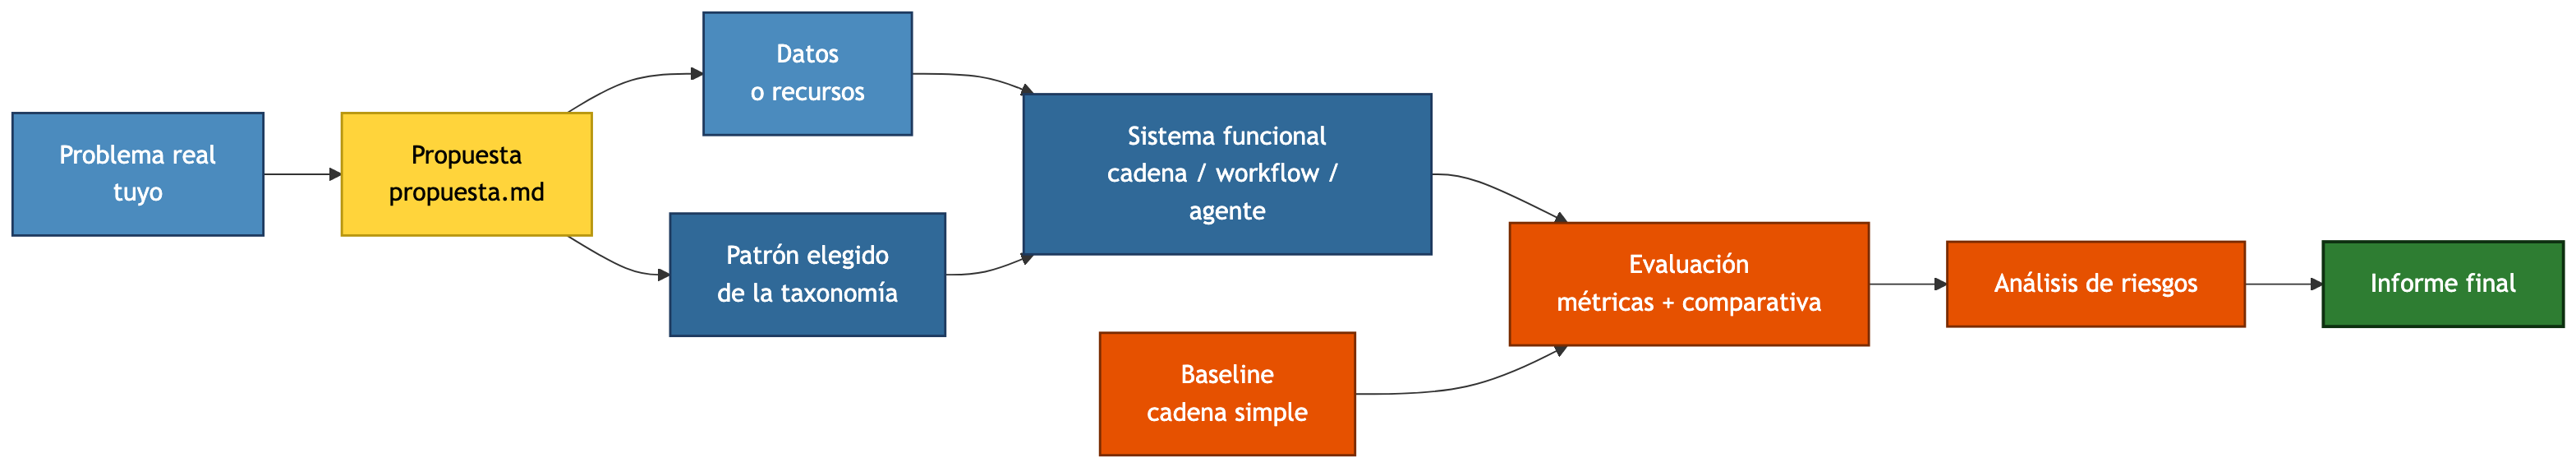
<figcaption>Figure 1</figcaption>
</figure>

## Fase 0 — Propuesta (`propuesta.md`)

Antes de escribir código, entrega una propuesta de una página que
responda:

1.  **El problema**: ¿qué problema real quieres resolver y para quién?
    Una frase clara + contexto.
2.  **Criterios de éxito medibles**: ¿cómo sabrás que el sistema lo
    resuelve? (p. ej. “responde correctamente ≥ 80 % de 50 preguntas de
    test”, “reduce a 3 llamadas de media el análisis de un informe”).
3.  **Patrón candidato**: ¿qué patrón de la taxonomía piensas usar y por
    qué? (puede cambiar luego, pero conviene decidirlo pronto).
4.  **Ruta de datos**: ¿de dónde salen los datos o recursos? (ver [Dónde
    conseguir datos](#sec-datos)).

Esta propuesta se corrige junto al proyecto final y vale dentro de la
dimensión “Propuesta y datos” de la rúbrica.

## Dónde conseguir datos

Los datos son un medio, no el objetivo: solo los necesitas si tu
problema requiere conocimiento externo (grounding). Si tu problema no es
de conocimiento —un planificador de tareas, un evaluador-optimizer de
redacción, un orquestador de workers sobre un repositorio de código, un
agente de análisis con pandas— los “datos” son simplemente los recursos
que tu problema necesite: código, tablas, APIs, documentos propios.

Para problemas de conocimiento, tienes tres rutas oficiales:

### Ruta 1 — Dataset real abierto

Catálogo de fuentes con licencia segura:

| Fuente | Qué encontrarás | Nota |
|------------------------|------------------------|------------------------|
| [Kaggle Datasets](https://www.kaggle.com/datasets) | Datasets de casi cualquier dominio | Comprueba la licencia de cada dataset |
| [Hugging Face Datasets](https://huggingface.co/datasets) | Corpus de texto, pares Q&A, datasets de instrucción | Ideal para RAG y evaluación |
| [UCI ML Repository](https://archive.ics.uci.edu) | Datasets clásicos de ML tabular | Bien documentados |
| [Google Dataset Search](https://datasetsearch.research.google.com) | Buscador transversal de datasets abiertos | Filtra por licencia |
| [datos.gob.es](https://datos.gob.es) / [data.europa.eu](https://data.europa.eu) | Datos abiertos de administraciones españolas y europeas | Mucho material tabular y documental |
| [PubMed](https://pubmed.ncbi.nlm.nih.gov) (API con `biopython`/`pymed`) | Abstracts biomédicos | Fuente alternativa de texto científico |
| [SEC EDGAR](https://www.sec.gov/edgar) | Informes financieros de empresas públicas | Formato HTML/TXT |
| Yahoo Finance (`yfinance`) / Alpha Vantage | Cotizaciones y datos de mercado | API con límites gratuitos |
| [Awesome Public Datasets](https://github.com/awesomedata/awesome-public-datasets) | Índice curado de datasets abiertos | Muy amplio |

> ⚠️ **Licencias**: documenta en tu informe la licencia del dataset que
> uses. Los datasets personales o empresariales con PII están fuera de
> alcance — ver [Bloque 4 — Privacidad](../bloque4/04c-privacidad.qmd).

### Ruta 2 — Datos sintéticos generados por ti

Es la ruta recomendada para problemas de conocimiento sin datos
disponibles. El módulo ya te da las herramientas:

- **Texto y tablas realistas**: prompting del LLM con JSON Schema
  ([02a](../bloque2/02a-prompt-engineering.qmd#sec-json-schema-datos-sint))
  o `faker` + `numpy` + `pandas`.
- **Tabular con fidelidad estadística**: SDV (CTGAN/TVAE), con
  presupuesto de privacidad diferencial ε
  ([03a](../bloque3/03a-datos-sinteticos.qmd)).
- **Historiales clínicos**:
  [Synthea](https://synthetichealth.github.io/synthea/).

El pipeline de generación sintética es parte del proyecto: documenta
cómo lo construiste, cómo validaste su calidad y por qué lo elegiste
frente a datos reales.

### Ruta 3 — Tu propio corpus

Si tu problema gira en torno a documentos reales que ya tienes o puedes
producir (manuales, normativas, informes de tu organización, artículos
de tu dominio), úsalos. Un corpus propio con ≥50 documentos o ≥10 000
filas tabulares es perfectamente válido.

## Problemas de ejemplo

Si no tienes un problema propio, inspírate en uno de estos (el patrón es
solo una sugerencia — la elección final es tuya):

| \# | Problema | Patrón que encaja | Fuentes sugeridas |
|------------------|------------------|------------------|------------------|
| 1 | Asistente para el análisis de cuentas anuales de una PYME | Routing (factual vs. analítico) | Ruta 2 (sintético) o SEC EDGAR |
| 2 | Triaje automático de tickets de soporte con respuesta sugerida | Routing + prompt chaining | Ruta 2 (faker) o Kaggle support tickets |
| 3 | Comparador de artículos científicos de un tema | Orchestrator-workers | PubMed / arXiv abstracts |
| 4 | Mentor personal de hábitos que aprende de tus errores | Reflection / Reflexion | Ruta 3 (tu propio diario) |
| 5 | Analizador de reviews para detectar insights de producto | ReAct + herramientas | Amazon Reviews / Kaggle |
| 6 | Planificador de viajes multi-ciudad con restricciones | Planning (plan-and-execute) | Ruta 2 (sintético) |
| 7 | Generador de informes de ventas con control de calidad editorial | Evaluator-optimizer | Ruta 2 (pandas + SDV) |
| 8 | Auditor de código con revisiones paralelas por aspecto | Parallelization (fan-out) | Ruta 3 (repositorio propio) |

Table 2: Problemas de ejemplo con patrón y datos sugeridos

## Evaluación

Tu informe debe demostrar, en este orden:

1.  **Métricas de la tarea**: las que definiste en la propuesta como
    criterios de éxito (precisión sobre un test, tasa de éxito de la
    tarea, nº de pasos, coste en llamadas…).
2.  **Comparativa contra baseline**: ejecuta el mismo problema con una
    cadena simple (LLM directo) y, si procede, con ReAct genérico
    (`create_agent` de 02e). Compara y explica *por qué* tu patrón gana
    o pierde: ¿menos llamadas? ¿más aciertos? ¿mejor manejo de errores?
3.  **RAGAS (solo si usas RAG)**: faithfulness, answer relevancy,
    context precision — objetivo compuesto \> 0,65, con desglose por
    tipo de pregunta. Ya lo dominas de [HPD 5](hpd5-entregable.qmd).
4.  **Iteración documentada**: al menos una iteración mostrando cómo un
    cambio (chunk size, prompt, top-k, temperatura, criterio del
    evaluador…) mejoró una métrica.

## Rúbrica

| Dimensión | Peso | Insuficiente (\< 5) | Suficiente (5-6,9) | Notable (7-8,9) | Sobresaliente (9-10) |
|------------|------------|------------|------------|------------|------------|
| **Propuesta y datos** | 15 % | Sin propuesta o sin criterios de éxito | Propuesta con problema y criterios básicos; datos o recursos mínimos | Propuesta clara con criterios medibles; ruta de datos justificada | Propuesta con criterios medibles, riesgos anticipados y generación de datos (si aplica), todo ello documentado y validado |
| **Patrón** | 20 % | Patrón inexistente o aplicado sin criterio | Patrón de la taxonomía aplicado correctamente | Patrón justificado con la guía de selección de 02f y comparado con alternativas | Justificación rigurosa + variante propia del patrón o propuesta de patrón nuevo con defensa de su valor |
| **Solución del problema** | 25 % | El sistema no resuelve el problema o falla en el flujo principal | Sistema funcional que resuelve el caso principal | Sistema robusto con manejo de errores, ≥2 herramientas y pipeline reproducible | Sistema modular, eficiente (coste/latencia considerados) y con decisiones de diseño documentadas |
| **Evaluación** | 15 % | Sin evaluación cuantitativa | Métricas de tarea reportadas | Métricas + comparativa contra baseline con análisis | Comparativa rigurosa contra baseline y alternativa (p. ej. ReAct vs. patrón elegido), con iteración documentada |
| **Gobernanza y ética** | 10 % | No se abordan riesgos | Se identifica un riesgo | Riesgo identificado y mitigación propuesta | Análisis de múltiples riesgos (alucinación, sesgo, privacidad, HITL) con ejemplos concretos |
| **Documentación** | 15 % | Código sin comentarios, sin README | README básico y código legible | Docstrings, diagrama de arquitectura, decisiones de diseño | Documentación completa: arquitectura, decisiones, informe de evaluación autocontenido y guía de reproducción |

> **Bonus — Idea novedosa** (hasta 1 punto adicional sobre la nota
> final): proponer una variante propia de un patrón, un patrón nuevo, o
> una combinación original de patrones, defendida con experimentos que
> demuestren su valor frente a las alternativas canónicas.

## Entregables

1.  **`propuesta.md`** — propuesta de una página (Fase 0).
2.  **`proyecto_final.ipynb`** — notebook con el sistema completo,
    celdas numeradas y las variables de corrección en la primera celda.
3.  **Datos o recursos** — datasets, corpus o scripts de generación
    (reales o sintéticos, con licencia documentada).
4.  **`informe_evaluacion.md`** — métricas, comparativa contra baseline,
    análisis de riesgos e iteración documentada.
5.  **`README.md`** — instrucciones de reproducción, requisitos,
    arquitectura y ejemplos de uso.

## Criterios de éxito

- El problema está definido con criterios de éxito medibles y el sistema
  los alcanza.
- El patrón elegido está justificado con la guía de selección de 02f y
  su valor se demuestra contra un baseline.
- Si usa RAG: métricas RAGAS \> 0,5, faithfulness \> 0,7 y mejora sobre
  baseline.
- El análisis de riesgos identifica al menos un caso real de alucinación
  o sesgo con su mitigación.
- El README permite reproducir el pipeline en menos de 15 minutos.

## Formato de entrega

1.  **Repositorio GitHub público** (recomendado) o archivo ZIP con todos
    los ficheros.
2.  El repositorio debe incluir: `propuesta.md`, `proyecto_final.ipynb`,
    `informe_evaluacion.md`, `README.md`, `datos/` (o script de
    generación) y `requirements.txt`.
3.  El notebook debe definir `proy_problema`, `proy_patron` y
    `proy_reporte` en la primera celda.

**Fecha límite:** consultar el calendario del módulo en la plataforma.

## Consejos finales

- **Empieza por la propuesta**: define problema y criterios de éxito
  antes de escribir código. Si no puedes medir “resolverlo”, no puedes
  evaluarlo.
- **Elige el nivel más simple que funcione**: el principio nº 1 de
  diseño de 02f es mantenerlo simple. Una cadena o un routing bien
  justificados puntúan más que un multi-agente injustificado.
- **Itera**: construye primero el baseline, luego tu patrón, y compara.
  Cada mejora debe estar documentada con su impacto en métricas.
- **Sé crítico con tu sistema**: el análisis de riesgos es tan
  importante como las métricas.
- **Cita tus fuentes**: datasets, modelos, papers y patrones usados — en
  tu informe y en las referencias del proyecto.